In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os

for dirpath, _, filenames in os.walk('/kaggle/input'):
    for f in filenames:
        full = os.path.join(dirpath, f)
        print(f"{os.path.getsize(full)/1e6:8.2f} MB  {full}")

    3.10 MB  /kaggle/input/datasets/nkongolo/ugransome-dataset/LIDETA.ipynb
   10.02 MB  /kaggle/input/datasets/nkongolo/ugransome-dataset/final(2).csv


In [2]:
import glob
import pandas as pd

csv_files = glob.glob('/kaggle/input/**/*.csv', recursive=True)
print("CSV files found:", csv_files)

DATA_PATH = csv_files[0]       # if 2 CSVs appear, change to [1]
df = pd.read_csv(DATA_PATH)

print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
print(df.columns.tolist())
df.head()

CSV files found: ['/kaggle/input/datasets/nkongolo/ugransome-dataset/final(2).csv']
Loaded: /kaggle/input/datasets/nkongolo/ugransome-dataset/final(2).csv
Shape: (149043, 14)
['Time', 'Protcol', 'Flag', 'Family', 'Clusters', 'SeddAddress', 'ExpAddress', 'BTC', 'USD', 'Netflow_Bytes', 'IPaddress', 'Threats', 'Port', 'Prediction']


,Time,Protcol,Flag,Family,Clusters,SeddAddress,ExpAddress,BTC,USD,Netflow_Bytes,IPaddress,Threats,Port,Prediction
0,50,TCP,A,WannaCry,1,1DA11mPS,1BonuSr7,1,500,5,A,Bonet,5061,SS
1,40,TCP,A,WannaCry,1,1DA11mPS,1BonuSr7,1,504,8,A,Bonet,5061,SS
2,30,TCP,A,WannaCry,1,1DA11mPS,1BonuSr7,1,508,7,A,Bonet,5061,SS
3,20,TCP,A,WannaCry,1,1DA11mPS,1BonuSr7,1,512,15,A,Bonet,5061,SS
4,57,TCP,A,WannaCry,1,1DA11mPS,1BonuSr7,1,516,9,A,Bonet,5061,SS


In [3]:
df.info()
print(df.isna().sum())
print(df.nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149043 entries, 0 to 149042
Data columns (total 14 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   Time           149043 non-null  int64 
 1   Protcol        149043 non-null  object
 2   Flag           149043 non-null  object
 3   Family         149043 non-null  object
 4   Clusters       149043 non-null  int64 
 5   SeddAddress    149043 non-null  object
 6   ExpAddress     149043 non-null  object
 7   BTC            149043 non-null  int64 
 8   USD            149043 non-null  int64 
 9   Netflow_Bytes  149043 non-null  int64 
 10  IPaddress      149043 non-null  object
 11  Threats        149043 non-null  object
 12  Port           149043 non-null  int64 
 13  Prediction     149043 non-null  object
dtypes: int64(6), object(8)
memory usage: 15.9+ MB
Time             0
Protcol          0
Flag             0
Family           0
Clusters         0
SeddAddress      0
ExpAddress       0
B

In [4]:
import os, glob, time, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); random.seed(SEED)

csvs = glob.glob('/kaggle/input/**/*.csv', recursive=True)
for c in csvs: print(c)

/kaggle/input/datasets/nkongolo/ugransome-dataset/final(2).csv


In [5]:
DATA_PATH = csvs[0]          # change the index if needed
df = pd.read_csv(DATA_PATH)
print(df.shape)
print(df.columns.tolist())
df.head()

(149043, 14)
['Time', 'Protcol', 'Flag', 'Family', 'Clusters', 'SeddAddress', 'ExpAddress', 'BTC', 'USD', 'Netflow_Bytes', 'IPaddress', 'Threats', 'Port', 'Prediction']


,Time,Protcol,Flag,Family,Clusters,SeddAddress,ExpAddress,BTC,USD,Netflow_Bytes,IPaddress,Threats,Port,Prediction
0,50,TCP,A,WannaCry,1,1DA11mPS,1BonuSr7,1,500,5,A,Bonet,5061,SS
1,40,TCP,A,WannaCry,1,1DA11mPS,1BonuSr7,1,504,8,A,Bonet,5061,SS
2,30,TCP,A,WannaCry,1,1DA11mPS,1BonuSr7,1,508,7,A,Bonet,5061,SS
3,20,TCP,A,WannaCry,1,1DA11mPS,1BonuSr7,1,512,15,A,Bonet,5061,SS
4,57,TCP,A,WannaCry,1,1DA11mPS,1BonuSr7,1,516,9,A,Bonet,5061,SS


In [6]:
TARGET = 'Prediction'

df = df.drop_duplicates().dropna().reset_index(drop=True)
print(df[TARGET].value_counts())

y = LabelEncoder().fit_transform(df[TARGET])
X = df.drop(columns=[TARGET]).copy()
for c in X.select_dtypes(include='object').columns:
    X[c] = LabelEncoder().fit_transform(X[c].astype(str))

feature_names = X.columns.tolist()
n_feat = len(feature_names)
X = X.values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEED)

# Smaller subset used ONLY inside the GA fitness (keeps it fast)
GA_N = min(10000, len(X_train))
idx = np.random.RandomState(SEED).choice(len(X_train), GA_N, replace=False)
Xga, yga = X_train[idx], y_train[idx]
Xga_tr, Xga_val, yga_tr, yga_val = train_test_split(
    Xga, yga, test_size=0.3, stratify=yga, random_state=SEED)
print("Features:", n_feat, "| GA subset:", GA_N)

Prediction
S     66380
A     42561
SS    40102
Name: count, dtype: int64
Features: 13 | GA subset: 10000


In [7]:
t = time.time()
rf0 = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED)
rf0.fit(X_train, y_train)
p = rf0.predict(X_test)
base_acc = accuracy_score(y_test, p)
base_f1 = f1_score(y_test, p, average='macro')
print(f"Baseline RF  acc={base_acc:.4f}  macroF1={base_f1:.4f}  time={time.time()-t:.1f}s")

Baseline RF  acc=0.9932  macroF1=0.9932  time=3.7s


In [10]:
N_EST = [50, 100, 150, 200]
DEPTH = [None, 5, 10, 15, 20, 30]
MSS   = [2, 5, 10]
MAXF  = ['sqrt', 'log2', 0.5]
HP_SIZES = [len(N_EST), len(DEPTH), len(MSS), len(MAXF)]

def repair(ind):
    if ind[:n_feat].sum() == 0:
        ind[np.random.randint(n_feat)] = 1
    return ind

def random_ind():
    mask = np.random.randint(0, 2, n_feat)
    hp = np.array([np.random.randint(s) for s in HP_SIZES])
    return repair(np.concatenate([mask, hp]))

def build_rf(ind):
    hp = ind[n_feat:]
    return RandomForestClassifier(
        n_estimators=N_EST[hp[0]], max_depth=DEPTH[hp[1]],
        min_samples_split=MSS[hp[2]], max_features=MAXF[hp[3]],
        n_jobs=-1, random_state=SEED)

cache = {}
def evaluate(ind):
    """returns (validation accuracy, number of selected features)"""
    key = tuple(ind)
    if key not in cache:
        cols = np.where(ind[:n_feat] == 1)[0]
        rf = build_rf(ind).fit(Xga_tr[:, cols], yga_tr)
        acc = accuracy_score(yga_val, rf.predict(Xga_val[:, cols]))
        cache[key] = (acc, len(cols))
    return cache[key]

# single-objective fitness: accuracy with a tiny penalty for many features
def fitness(ind):
    acc, k = evaluate(ind)
    return acc - 0.01 * (k / n_feat)

# multi-objective (both minimised): error rate, fraction of features
def objs(ind):
    acc, k = evaluate(ind)
    return np.array([1 - acc, k / n_feat])

def tourn_idx(fit, k=3):
    idx = np.random.randint(len(fit), size=k)
    return idx[np.argmax(fit[idx])]

def crossover(a, b):                       # uniform crossover
    m = np.random.rand(len(a)) < 0.5
    return np.where(m, a, b), np.where(m, b, a)

def mutate(ind, pm):
    ind = ind.copy()
    for i in range(n_feat):
        if np.random.rand() < pm: ind[i] = 1 - ind[i]
    for j, s in enumerate(HP_SIZES):
        if np.random.rand() < pm * 3: ind[n_feat + j] = np.random.randint(s)
    return repair(ind)

POP, GENS = 16, 10       # increase (e.g. 30 / 25) for better results, if time allows
results = {}

In [11]:
N_EST = [50, 100, 150, 200]
DEPTH = [None, 5, 10, 15, 20, 30]
MSS   = [2, 5, 10]
MAXF  = ['sqrt', 'log2', 0.5]
HP_SIZES = [len(N_EST), len(DEPTH), len(MSS), len(MAXF)]

def repair(ind):
    if ind[:n_feat].sum() == 0:
        ind[np.random.randint(n_feat)] = 1
    return ind

def random_ind():
    mask = np.random.randint(0, 2, n_feat)
    hp = np.array([np.random.randint(s) for s in HP_SIZES])
    return repair(np.concatenate([mask, hp]))

def build_rf(ind):
    hp = ind[n_feat:]
    return RandomForestClassifier(
        n_estimators=N_EST[hp[0]], max_depth=DEPTH[hp[1]],
        min_samples_split=MSS[hp[2]], max_features=MAXF[hp[3]],
        n_jobs=-1, random_state=SEED)

cache = {}
def evaluate(ind):
    """returns (validation accuracy, number of selected features)"""
    key = tuple(ind)
    if key not in cache:
        cols = np.where(ind[:n_feat] == 1)[0]
        rf = build_rf(ind).fit(Xga_tr[:, cols], yga_tr)
        acc = accuracy_score(yga_val, rf.predict(Xga_val[:, cols]))
        cache[key] = (acc, len(cols))
    return cache[key]

# single-objective fitness: accuracy with a tiny penalty for many features
def fitness(ind):
    acc, k = evaluate(ind)
    return acc - 0.01 * (k / n_feat)

# multi-objective (both minimised): error rate, fraction of features
def objs(ind):
    acc, k = evaluate(ind)
    return np.array([1 - acc, k / n_feat])

def tourn_idx(fit, k=3):
    idx = np.random.randint(len(fit), size=k)
    return idx[np.argmax(fit[idx])]

def crossover(a, b):                       # uniform crossover
    m = np.random.rand(len(a)) < 0.5
    return np.where(m, a, b), np.where(m, b, a)

def mutate(ind, pm):
    ind = ind.copy()
    for i in range(n_feat):
        if np.random.rand() < pm: ind[i] = 1 - ind[i]
    for j, s in enumerate(HP_SIZES):
        if np.random.rand() < pm * 3: ind[n_feat + j] = np.random.randint(s)
    return repair(ind)

POP, GENS = 16, 10       # increase (e.g. 30 / 25) for better results, if time allows
results = {}

In [12]:
def sga(pop_size=POP, gens=GENS, pc=0.8, pm=0.1, elite=1):
    pop = [random_ind() for _ in range(pop_size)]
    hist = []
    for g in range(gens):
        fit = np.array([fitness(i) for i in pop])
        hist.append(fit.max())
        print(f"SGA gen {g+1}/{gens} best={fit.max():.4f}")
        new = [pop[i].copy() for i in np.argsort(-fit)[:elite]]
        while len(new) < pop_size:
            p1, p2 = pop[tourn_idx(fit)], pop[tourn_idx(fit)]
            c1, c2 = crossover(p1, p2) if np.random.rand() < pc else (p1.copy(), p2.copy())
            new += [mutate(c1, pm), mutate(c2, pm)]
        pop = new[:pop_size]
    fit = np.array([fitness(i) for i in pop])
    return pop[int(np.argmax(fit))], hist

t = time.time()
best, hist = sga()
results['SGA'] = dict(ind=best, hist=hist, time=time.time()-t)

SGA gen 1/10 best=0.9715
SGA gen 2/10 best=0.9715
SGA gen 3/10 best=0.9731
SGA gen 4/10 best=0.9745
SGA gen 5/10 best=0.9751
SGA gen 6/10 best=0.9751
SGA gen 7/10 best=0.9751
SGA gen 8/10 best=0.9751
SGA gen 9/10 best=0.9751
SGA gen 10/10 best=0.9751


In [14]:
def aga(pop_size=POP, gens=GENS, k1=0.9, k2=0.1, k3=0.9, k4=0.1, elite=1):
    pop = [random_ind() for _ in range(pop_size)]
    hist = []
    for g in range(gens):
        fit = np.array([fitness(i) for i in pop])
        fmax, favg = fit.max(), fit.mean()
        den = max(fmax - favg, 1e-9)
        hist.append(fmax)
        print(f"AGA gen {g+1}/{gens} best={fmax:.4f}")
        new = [pop[i].copy() for i in np.argsort(-fit)[:elite]]
        while len(new) < pop_size:
            i1, i2 = tourn_idx(fit), tourn_idx(fit)
            fp = max(fit[i1], fit[i2])
            pc = k1 * (fmax - fp) / den if fp >= favg else k3
            pm = k2 * (fmax - fp) / den if fp >= favg else k4
            if np.random.rand() < pc: c1, c2 = crossover(pop[i1], pop[i2])
            else: c1, c2 = pop[i1].copy(), pop[i2].copy()
            new += [mutate(c1, pm), mutate(c2, pm)]
        pop = new[:pop_size]
    fit = np.array([fitness(i) for i in pop])
    return pop[int(np.argmax(fit))], hist

t = time.time()
best, hist = aga()
results['AGA'] = dict(ind=best, hist=hist, time=time.time()-t)

AGA gen 1/10 best=0.9702
AGA gen 2/10 best=0.9702
AGA gen 3/10 best=0.9702
AGA gen 4/10 best=0.9735
AGA gen 5/10 best=0.9735
AGA gen 6/10 best=0.9735
AGA gen 7/10 best=0.9735
AGA gen 8/10 best=0.9735
AGA gen 9/10 best=0.9735
AGA gen 10/10 best=0.9735


In [15]:
def local_search(ind, iters=6):
    best, bf = ind.copy(), fitness(ind)
    for _ in range(iters):
        cand = best.copy()
        if np.random.rand() < 0.6:
            j = np.random.randint(n_feat); cand[j] = 1 - cand[j]
        else:
            j = np.random.randint(len(HP_SIZES))
            cand[n_feat + j] = np.random.randint(HP_SIZES[j])
        cand = repair(cand); cf = fitness(cand)
        if cf > bf: best, bf = cand, cf
    return best

def memetic(pop_size=POP, gens=GENS, pc=0.8, pm=0.1, ls_top=3):
    pop = [random_ind() for _ in range(pop_size)]
    hist = []
    for g in range(gens):
        fit = np.array([fitness(i) for i in pop])
        # local search on the best individuals (Lamarckian)
        for i in np.argsort(-fit)[:ls_top]:
            pop[i] = local_search(pop[i])
        fit = np.array([fitness(i) for i in pop])
        hist.append(fit.max())
        print(f"Memetic gen {g+1}/{gens} best={fit.max():.4f}")
        new = [pop[int(np.argmax(fit))].copy()]
        while len(new) < pop_size:
            p1, p2 = pop[tourn_idx(fit)], pop[tourn_idx(fit)]
            c1, c2 = crossover(p1, p2) if np.random.rand() < pc else (p1.copy(), p2.copy())
            new += [mutate(c1, pm), mutate(c2, pm)]
        pop = new[:pop_size]
    fit = np.array([fitness(i) for i in pop])
    return pop[int(np.argmax(fit))], hist

t = time.time()
best, hist = memetic()
results['Memetic'] = dict(ind=best, hist=hist, time=time.time()-t)

Memetic gen 1/10 best=0.9714
Memetic gen 2/10 best=0.9742
Memetic gen 3/10 best=0.9744
Memetic gen 4/10 best=0.9751
Memetic gen 5/10 best=0.9751
Memetic gen 6/10 best=0.9774
Memetic gen 7/10 best=0.9774
Memetic gen 8/10 best=0.9776
Memetic gen 9/10 best=0.9776
Memetic gen 10/10 best=0.9783


In [17]:
def dominates(a, b):
    return np.all(a <= b) and np.any(a < b)

def fast_nd_sort(F):
    n = len(F); S = [[] for _ in range(n)]; cnt = np.zeros(n, int); fronts = [[]]
    for p in range(n):
        for q in range(n):
            if p == q: continue
            if dominates(F[p], F[q]): S[p].append(q)
            elif dominates(F[q], F[p]): cnt[p] += 1
        if cnt[p] == 0: fronts[0].append(p)
    i = 0
    while fronts[i]:
        nxt = []
        for p in fronts[i]:
            for q in S[p]:
                cnt[q] -= 1
                if cnt[q] == 0: nxt.append(q)
        i += 1; fronts.append(nxt)
    return fronts[:-1]

def crowding(F, front):
    d = np.zeros(len(front))
    for m in range(F.shape[1]):
        order = np.argsort(F[front, m])
        d[order[0]] = d[order[-1]] = np.inf
        rng = F[front[order[-1]], m] - F[front[order[0]], m]
        if rng == 0: continue
        for k in range(1, len(front) - 1):
            d[order[k]] += (F[front[order[k+1]], m] - F[front[order[k-1]], m]) / rng
    return d

def best_of_front(front):
    """most accurate individual; ties -> fewer features"""
    return max(front, key=lambda i: (evaluate(i)[0], -evaluate(i)[1]))

In [20]:
def nsga2(pop_size=POP, gens=GENS, pc=0.9, pm=0.1):
    pop = [random_ind() for _ in range(pop_size)]
    for g in range(gens):
        F = np.array([objs(i) for i in pop])
        fronts = fast_nd_sort(F)
        rank = np.zeros(len(pop), int); crowd = np.zeros(len(pop))
        for r, fr in enumerate(fronts):
            rank[fr] = r; crowd[fr] = crowding(F, fr)
        def pick():
            a, b = np.random.randint(len(pop), size=2)
            if rank[a] != rank[b]: return a if rank[a] < rank[b] else b
            return a if crowd[a] > crowd[b] else b
        kids = []
        while len(kids) < pop_size:
            p1, p2 = pop[pick()], pop[pick()]
            c1, c2 = crossover(p1, p2) if np.random.rand() < pc else (p1.copy(), p2.copy())
            kids += [mutate(c1, pm), mutate(c2, pm)]
        union = pop + kids[:pop_size]
        FU = np.array([objs(i) for i in union])
        new = []
        for fr in fast_nd_sort(FU):
            if len(new) + len(fr) <= pop_size: new += fr
            else:
                order = np.argsort(-crowding(FU, fr))
                new += [fr[i] for i in order[:pop_size - len(new)]]
                break
        pop = [union[i] for i in new]
        print(f"NSGA-II gen {g+1}/{gens} best acc={max(evaluate(i)[0] for i in pop):.4f}")
    F = np.array([objs(i) for i in pop])
    return [pop[i] for i in fast_nd_sort(F)[0]]

t = time.time()
pareto = nsga2()
results['NSGA-II'] = dict(ind=best_of_front(pareto), pareto=pareto, time=time.time()-t)
print("Pareto front (acc, #features):", sorted({evaluate(i) for i in pareto}, reverse=True))

NSGA-II gen 1/10 best acc=0.9803
NSGA-II gen 2/10 best acc=0.9810
NSGA-II gen 3/10 best acc=0.9810
NSGA-II gen 4/10 best acc=0.9830
NSGA-II gen 5/10 best acc=0.9830
NSGA-II gen 6/10 best acc=0.9833
NSGA-II gen 7/10 best acc=0.9833
NSGA-II gen 8/10 best acc=0.9833
NSGA-II gen 9/10 best acc=0.9833
NSGA-II gen 10/10 best acc=0.9833
Pareto front (acc, #features): [(0.9833333333333333, 7), (0.9813333333333333, 6), (0.9713333333333334, 5), (0.9683333333333334, 4), (0.9566666666666667, 3), (0.9476666666666667, 2), (0.8056666666666666, 1)]


In [22]:
def spea2_fitness(F):
    n = len(F)
    dom = np.array([[dominates(F[i], F[j]) for j in range(n)] for i in range(n)])
    S = dom.sum(1)
    R = np.array([S[dom[:, i]].sum() for i in range(n)])
    D = np.linalg.norm(F[:, None, :] - F[None, :, :], axis=2)
    k = max(1, int(np.sqrt(n)))
    sigma = np.sort(D, axis=1)[:, k]
    return R + 1.0 / (sigma + 2.0), D

def spea2_select(F, size):
    fit, D = spea2_fitness(F)
    sel = [int(i) for i in np.where(fit < 1)[0]]
    if len(sel) < size:
        sel += [int(i) for i in np.argsort(fit) if i not in sel][:size - len(sel)]
    while len(sel) > size:                       # truncation by nearest-neighbour distance
        sub = D[np.ix_(sel, sel)].copy(); np.fill_diagonal(sub, np.inf)
        srt = np.sort(sub, axis=1)
        sel.pop(min(range(len(sel)), key=lambda i: tuple(srt[i])))
    return sel

def spea2(pop_size=POP, arch_size=POP, gens=GENS, pc=0.9, pm=0.1):
    pop = [random_ind() for _ in range(pop_size)]; archive = []
    for g in range(gens):
        union = pop + archive
        FU = np.array([objs(i) for i in union])
        archive = [union[i] for i in spea2_select(FU, arch_size)]
        FA = np.array([objs(i) for i in archive])
        fitA, _ = spea2_fitness(FA)
        def pick():
            a, b = np.random.randint(len(archive), size=2)
            return a if fitA[a] < fitA[b] else b      # lower SPEA2 fitness = better
        kids = []
        while len(kids) < pop_size:
            p1, p2 = archive[pick()], archive[pick()]
            c1, c2 = crossover(p1, p2) if np.random.rand() < pc else (p1.copy(), p2.copy())
            kids += [mutate(c1, pm), mutate(c2, pm)]
        pop = kids[:pop_size]
        print(f"SPEA2 gen {g+1}/{gens} best acc={max(evaluate(i)[0] for i in archive):.4f}")
    union = pop + archive
    FU = np.array([objs(i) for i in union])
    archive = [union[i] for i in spea2_select(FU, arch_size)]
    FA = np.array([objs(i) for i in archive])
    return [archive[i] for i in fast_nd_sort(FA)[0]]

t = time.time()
pareto = spea2()
results['SPEA2'] = dict(ind=best_of_front(pareto), pareto=pareto, time=time.time()-t)
print("Pareto front (acc, #features):", sorted({evaluate(i) for i in pareto}, reverse=True))

SPEA2 gen 1/10 best acc=0.9790
SPEA2 gen 2/10 best acc=0.9810
SPEA2 gen 3/10 best acc=0.9810
SPEA2 gen 4/10 best acc=0.9810
SPEA2 gen 5/10 best acc=0.9810
SPEA2 gen 6/10 best acc=0.9810
SPEA2 gen 7/10 best acc=0.9813
SPEA2 gen 8/10 best acc=0.9813
SPEA2 gen 9/10 best acc=0.9813
SPEA2 gen 10/10 best acc=0.9813
Pareto front (acc, #features): [(0.9826666666666667, 8), (0.981, 7), (0.9783333333333334, 5), (0.9606666666666667, 4), (0.958, 3), (0.942, 2)]


SGA: n_estimators=200, max_depth=20, min_samples_split=2, max_features=sqrt
   selected: ['Time', 'Protcol', 'Flag', 'Family', 'Clusters', 'BTC', 'USD', 'Netflow_Bytes', 'Threats']
AGA: n_estimators=150, max_depth=None, min_samples_split=2, max_features=0.5
   selected: ['Protcol', 'Flag', 'Family', 'Clusters', 'BTC', 'Netflow_Bytes', 'Threats', 'Port']
Memetic: n_estimators=200, max_depth=20, min_samples_split=5, max_features=log2
   selected: ['Family', 'Clusters', 'BTC', 'USD', 'Netflow_Bytes', 'IPaddress', 'Threats']
NSGA-II: n_estimators=200, max_depth=15, min_samples_split=5, max_features=log2
   selected: ['Family', 'Clusters', 'BTC', 'USD', 'Netflow_Bytes', 'IPaddress', 'Threats']
SPEA2: n_estimators=150, max_depth=None, min_samples_split=5, max_features=log2
   selected: ['Protcol', 'Family', 'Clusters', 'BTC', 'USD', 'Netflow_Bytes', 'IPaddress', 'Threats']


,Method,Accuracy,MacroF1,Features,GA_time_s
0,Baseline RF,0.993246,0.993238,13,0.0
1,NSGA-II,0.991792,0.991784,7,139.3
2,SPEA2,0.990428,0.990475,8,126.3
3,Memetic,0.990159,0.990189,7,252.1
4,SGA,0.990137,0.990181,9,120.9
5,AGA,0.985373,0.985481,8,27.1


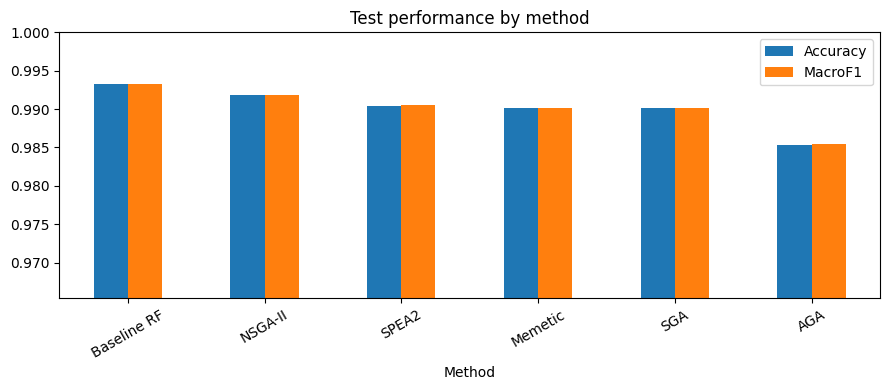

In [23]:
rows = [dict(Method='Baseline RF', Accuracy=base_acc, MacroF1=base_f1,
             Features=n_feat, GA_time_s=0)]
for name, r in results.items():
    ind = r['ind']; cols = np.where(ind[:n_feat] == 1)[0]
    rf = build_rf(ind).fit(X_train[:, cols], y_train)
    pred = rf.predict(X_test[:, cols])
    rows.append(dict(Method=name,
                     Accuracy=accuracy_score(y_test, pred),
                     MacroF1=f1_score(y_test, pred, average='macro'),
                     Features=len(cols), GA_time_s=round(r['time'], 1)))
    hp = ind[n_feat:]
    print(f"{name}: n_estimators={N_EST[hp[0]]}, max_depth={DEPTH[hp[1]]}, "
          f"min_samples_split={MSS[hp[2]]}, max_features={MAXF[hp[3]]}")
    print("   selected:", [feature_names[i] for i in cols])

comp = pd.DataFrame(rows).sort_values('Accuracy', ascending=False).reset_index(drop=True)
display(comp)

comp.plot(x='Method', y=['Accuracy', 'MacroF1'], kind='bar', figsize=(9, 4),
          ylim=(max(0, comp.Accuracy.min() - 0.02), 1.0))
plt.title('Test performance by method'); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

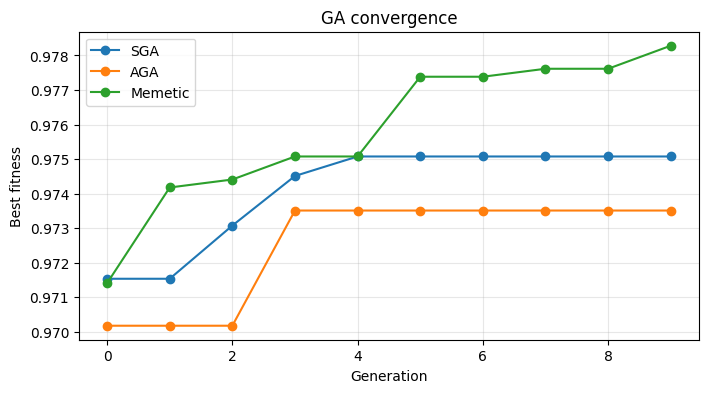

In [26]:
plt.figure(figsize=(8, 4))
for n in ['SGA', 'AGA', 'Memetic']:
    plt.plot(results[n]['hist'], label=n, marker='o')
plt.xlabel('Generation'); plt.ylabel('Best fitness'); plt.legend(); plt.grid(alpha=.3)
plt.title('GA convergence'); plt.show()

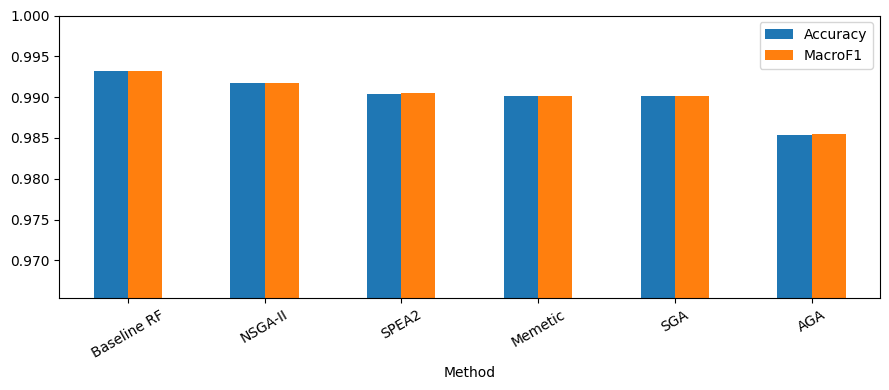

In [27]:
import os, json, joblib

os.makedirs('/kaggle/working', exist_ok=True)

# comparison table
comp.to_csv('/kaggle/working/results_comparison.csv', index=False)

# chart
comp.plot(x='Method', y=['Accuracy', 'MacroF1'], kind='bar', figsize=(9, 4),
          ylim=(max(0, comp.Accuracy.min() - 0.02), 1.0))
plt.xticks(rotation=30); plt.tight_layout()
plt.savefig('/kaggle/working/comparison.png', dpi=150)
plt.show()

In [28]:
best_name = comp.iloc[0]['Method']

if best_name == 'Baseline RF':
    best_model, best_cols = rf0, list(range(n_feat))
else:
    ind = results[best_name]['ind']
    best_cols = np.where(ind[:n_feat] == 1)[0].tolist()
    best_model = build_rf(ind).fit(X_train[:, best_cols], y_train)

joblib.dump(best_model, '/kaggle/working/best_rf_model.pkl')
json.dump({'method': best_name,
           'features': [feature_names[i] for i in best_cols]},
          open('/kaggle/working/best_features.json', 'w'))
print("Saved:", best_name)

Saved: Baseline RF
